# Contextual-cluster Atlas-DeePC

This notebook asks whether Contextual Sampling can be compressed into an offline atlas: preserve its reference-aware $Y_p/Y_f$ notion of relevance, but avoid scoring all 37,800 Hankel columns and rebuilding an SVD at every control step.

The final comparison uses **500 paired Reacher seeds, 211--710**, the same random-walk offline library, 48-chart physical atlas, graph-routed references, graph-compatible goal construction, top/support count 200, DeePC QP, solver, horizons, costs, constraints, and strict success definition as `comparison.ipynb`. A final section varies only the cached affine basis rank.

In [1]:
from pathlib import Path
import json, math, statistics, sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
assert (ROOT / 'src').exists(), 'Run from the atlas_deepc_reacher project root.'
sys.path.insert(0, str(ROOT / 'src'))

RESULT_ROOT = ROOT / 'experiments' / 'routed_deepc_iid'
DEV_BASELINE_DIR = RESULT_ROOT / 'clustering_jointconfig48_benchmark111_210'
DEV_ALWAYS64_DIR = RESULT_ROOT / 'contextual_cluster_dev_global64_always'
DEV_ALWAYS128_DIR = RESULT_ROOT / 'contextual_cluster_dev_global128_always'
DEV_TRIGGER64_DIR = RESULT_ROOT / 'contextual_cluster_dev_global64_triggered'
DEV_TRIGGER128_DIR = RESULT_ROOT / 'contextual_cluster_dev_global128_triggered'
EVAL_ALWAYS64_DIR = RESULT_ROOT / 'contextual_cluster_eval211_710_global64_always'
EVAL_ALWAYS128_DIR = RESULT_ROOT / 'contextual_cluster_eval211_710_global128_always'
EVAL_TRIGGER64_DIR = RESULT_ROOT / 'contextual_cluster_eval211_710_global64_triggered'
EVAL_TRIGGER128_DIR = RESULT_ROOT / 'contextual_cluster_eval211_710_global128_triggered'
EVAL_CLUSTER_DIR = EVAL_TRIGGER128_DIR
DEV_RANK_DIRS = {
    20: RESULT_ROOT / 'contextual_cluster_rank_dev20',
    30: RESULT_ROOT / 'contextual_cluster_rank_dev30',
    40: RESULT_ROOT / 'contextual_cluster_rank_dev40',
    45: RESULT_ROOT / 'contextual_cluster_rank_dev45',
    46: RESULT_ROOT / 'contextual_cluster_rank_dev46',
    47: RESULT_ROOT / 'contextual_cluster_rank_dev47',
    48: RESULT_ROOT / 'contextual_cluster_rank_dev48',
    49: RESULT_ROOT / 'contextual_cluster_rank_dev49',
    50: RESULT_ROOT / 'contextual_cluster_rank_dev50',
    51: RESULT_ROOT / 'contextual_cluster_rank_dev51',
    52: RESULT_ROOT / 'contextual_cluster_rank_dev52',
    53: RESULT_ROOT / 'contextual_cluster_rank_dev53',
    54: RESULT_ROOT / 'contextual_cluster_rank_dev54',
    60: DEV_TRIGGER128_DIR,
}
EVAL_RANK_DIRS = {
    40: RESULT_ROOT / 'contextual_cluster_rank_eval40_211_710',
    45: RESULT_ROOT / 'contextual_cluster_rank_eval45_211_710',
    47: RESULT_ROOT / 'contextual_cluster_rank_eval47_211_710',
    60: EVAL_CLUSTER_DIR,
}
COMPARISON_SUMMARY = ROOT / 'experiments/deepc_algorithm_comparison/six_way_svd_heldout111_1210_n200_rank60/summary.json'
TIMING_PATH = EVAL_CLUSTER_DIR / 'controlled_serial_timing.json'
RANK_TIMING_PATH = EVAL_RANK_DIRS[47] / 'controlled_serial_rank_timing.json'
DEV_SEEDS = list(range(111, 211))
EVAL_SEEDS = list(range(211, 711))

required = [
    DEV_BASELINE_DIR / 'summary.json', DEV_ALWAYS64_DIR / 'summary.json',
    DEV_ALWAYS128_DIR / 'summary.json',
    DEV_TRIGGER64_DIR / 'summary.json', DEV_TRIGGER128_DIR / 'summary.json',
    EVAL_ALWAYS64_DIR / 'summary.json', EVAL_ALWAYS128_DIR / 'summary.json',
    EVAL_TRIGGER64_DIR / 'summary.json', EVAL_TRIGGER128_DIR / 'summary.json',
    COMPARISON_SUMMARY,
    *[path / 'summary.json' for path in DEV_RANK_DIRS.values()],
    *[path / 'summary.json' for path in EVAL_RANK_DIRS.values()],
    RANK_TIMING_PATH,
]
assert all(path.exists() for path in required), [path for path in required if not path.exists()]
print('Evaluation panel:', f'{EVAL_SEEDS[0]}-{EVAL_SEEDS[-1]} ({len(EVAL_SEEDS)} paired seeds)')

Evaluation panel: 211-710 (500 paired seeds)


## 1. From online contextual retrieval to an offline atlas

Contextual-aware DPC computes, for every complete Hankel column $i$,

$$
s_i(t)=z\!\left(\|Y_{p,i}-y_{\mathrm{ini},t}\|_2\right)
+z\!\left(\|Y_{f,i}-r_t\|_Q\right),
$$

retains the 200 smallest scores, and rebuilds a centered rank-60 SVD online.

The contextual-cluster atlas instead embeds every offline column once using its normalized past output and $Q$-weighted future output, then applies MiniBatch K-means with $K_c=128$. For prototype $c$, its 200 nearest complete input-output columns define a cached matrix

$$
A_c=(\bar h_c,V_{c,60},g_c^{\min},g_c^{\max}).
$$

During deployment, the physical 48-chart atlas still localizes the arm and graph routing still constructs the waypoint or terminal reference. After a causal terminal stall, only 128 cached prototypes are scored with the same past/future decomposition, and DeePC receives the selected cached $A_c$. There is no online Hankel-column search and no online SVD.

### Controller variants in this notebook

All six variants use the same offline random-walk data, graph-routed reference, DeePC objective, constraints, horizon, and strict success definition. They differ only in the behavioral matrix supplied to the DeePC QP:

| Method | Matrix supplied to DeePC at time $t$ | Contextual activation |
|---|---|---|
| Baseline physical Atlas | Cached basis $B^{\mathrm{phys}}_{k_t}$ of the current 48-chart physical cluster | Never |
| Always-on contextual Atlas, 64 | $B^{\mathrm{ctx}}_{c_t^*}$ selected by scoring 64 prototypes | Every step |
| Always-on contextual Atlas, 128 | $B^{\mathrm{ctx}}_{c_t^*}$ selected by scoring 128 prototypes | Every step |
| Triggered contextual Atlas, 64 | $B^{\mathrm{phys}}_{k_t}$ before a terminal stall; then a 64-prototype $B^{\mathrm{ctx}}_{c_t^*}$ | After trigger |
| Triggered contextual Atlas, 128 | $B^{\mathrm{phys}}_{k_t}$ before a terminal stall; then a 128-prototype $B^{\mathrm{ctx}}_{c_t^*}$ | After trigger |
| Contextual-aware DPC | Rank-60 basis rebuilt from the 200 lowest-scoring global Hankel columns | Every step |

For the contextual-atlas variants,

$$
c_t^*=\arg\min_c\left[
z\!\left(\|\bar Y_{p,c}-y_{\mathrm{ini},t}\|_2\right)
+z\!\left(\|\bar Y_{f,c}-r_t\|_Q\right)
\right].
$$

The physical atlas continues to perform localization and graph routing in every method labeled Atlas. “Always-on” and “triggered” describe only which cached behavioral basis is sent to DeePC.

In [2]:
def load_rows(path):
    payload = json.loads(path.read_text())
    return payload, {int(row['seed']): row for row in payload['results']}

def strict(row):
    return bool(row['success_30'] and row['success_100'])

dev_baseline_payload, dev_baseline = load_rows(DEV_BASELINE_DIR / 'summary.json')
dev_always_payload, dev_always = load_rows(DEV_ALWAYS64_DIR / 'summary.json')
dev_always128_payload, dev_always128 = load_rows(DEV_ALWAYS128_DIR / 'summary.json')
dev_t64_payload, dev_t64 = load_rows(DEV_TRIGGER64_DIR / 'summary.json')
dev_t128_payload, dev_t128 = load_rows(DEV_TRIGGER128_DIR / 'summary.json')
eval_always64_payload, eval_always64 = load_rows(EVAL_ALWAYS64_DIR / 'summary.json')
eval_always128_payload, eval_always128 = load_rows(EVAL_ALWAYS128_DIR / 'summary.json')
eval_trigger64_payload, eval_trigger64 = load_rows(EVAL_TRIGGER64_DIR / 'summary.json')
eval_cluster_payload, eval_cluster = load_rows(EVAL_TRIGGER128_DIR / 'summary.json')

comparison = json.loads(COMPARISON_SUMMARY.read_text())
contextual_all = {int(row['seed']): row for row in comparison['method_summaries']['contextual_graph_svd']}
atlas_all = {int(row['seed']): row for row in comparison['method_summaries']['atlas']}
eval_contextual = {seed: contextual_all[seed] for seed in EVAL_SEEDS}
eval_atlas = {seed: atlas_all[seed] for seed in EVAL_SEEDS}

for rows in (eval_always64, eval_always128, eval_trigger64, eval_cluster):
    assert set(rows) == set(EVAL_SEEDS)
assert eval_cluster_payload['fairness_audit']['offline_stabilized_episode_count'] == 0
assert all(not row['online_nearest_trajectory_retrieval'] for row in eval_cluster.values())
assert all(not row['online_svd_rebuild'] for row in eval_cluster.values())
assert all(row['online_hankel_columns_scored'] == 0 for row in eval_cluster.values())
display(pd.Series({
    'offline seed range': str(eval_cluster_payload['fairness_audit']['data_seed_range']),
    'offline stabilized episodes': eval_cluster_payload['fairness_audit']['offline_stabilized_episode_count'],
    'physical charts': 48,
    'contextual prototypes': eval_cluster_payload['artifact']['prototype_count'],
    'complete columns per cached basis': eval_cluster_payload['artifact']['support_columns'],
    'rank': eval_cluster_payload['config']['svd_rank'],
    'online Hankel columns scored': 0,
    'online SVD rebuild': False,
    'fitted dynamics / IK / fallback': 'none',
}))

offline seed range                   [2026, 2225]
offline stabilized episodes                     0
physical charts                                48
contextual prototypes                         128
complete columns per cached basis             200
rank                                           60
online Hankel columns scored                    0
online SVD rebuild                          False
fitted dynamics / IK / fallback              none
dtype: object

## 2. Development search

,successes,trials,success rate
method,,,
Baseline Atlas,94,100,94.0%
"Always-on global VQ, 64",74,100,74.0%
"Always-on global VQ, 128",92,100,92.0%
"Triggered global VQ, 64",95,100,95.0%
"Triggered global VQ, 128 (selected)",97,100,97.0%
Contextual-aware DPC,97,100,97.0%


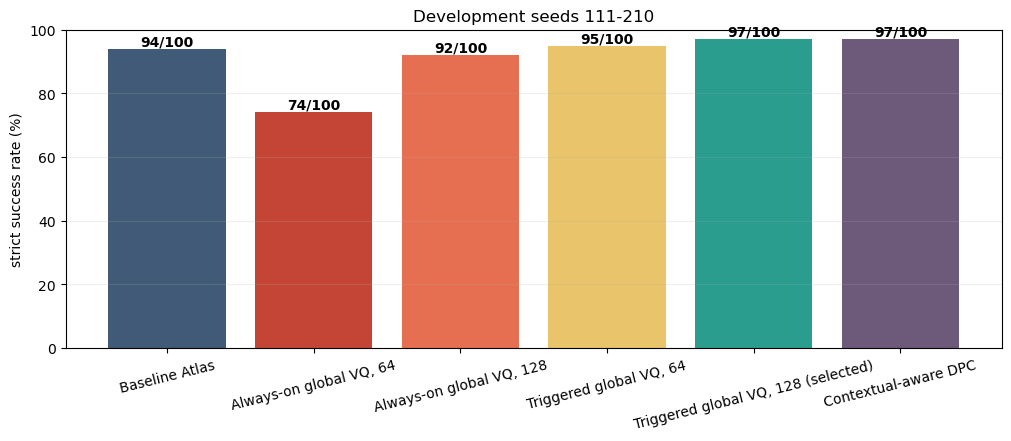

In [3]:
dev_methods = {
    'Baseline Atlas': dev_baseline,
    'Always-on global VQ, 64': dev_always,
    'Always-on global VQ, 128': dev_always128,
    'Triggered global VQ, 64': dev_t64,
    'Triggered global VQ, 128 (selected)': dev_t128,
    'Contextual-aware DPC': {seed: contextual_all[seed] for seed in DEV_SEEDS},
}
development_rows = []
for method, rows in dev_methods.items():
    count = sum(strict(rows[seed]) for seed in DEV_SEEDS)
    development_rows.append({'method': method, 'successes': count, 'trials': 100, 'success rate': count / 100})
development_table = pd.DataFrame(development_rows).set_index('method')
display(development_table.style.format({'success rate': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(10, 4.3), constrained_layout=True)
colors = ['#415a77', '#c44536', '#e76f51', '#e9c46a', '#2a9d8f', '#6d597a']
bars = ax.bar(development_table.index, 100 * development_table['success rate'], color=colors)
ax.set(ylabel='strict success rate (%)', ylim=(0, 100), title='Development seeds 111-210')
ax.tick_params(axis='x', rotation=14)
ax.grid(axis='y', alpha=0.2)
for bar, value in zip(bars, development_table['successes']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{value}/100', ha='center', fontweight='bold')
plt.show()

In [4]:
def development_pair(first_name, first, second_name, second):
    first_only = [s for s in DEV_SEEDS if strict(first[s]) and not strict(second[s])]
    second_only = [s for s in DEV_SEEDS if not strict(first[s]) and strict(second[s])]
    discordant = len(first_only) + len(second_only)
    if discordant:
        tail = sum(math.comb(discordant, k) for k in range(min(len(first_only), len(second_only)) + 1))
        p_value = min(1.0, 2.0 * tail / 2**discordant)
    else:
        p_value = 1.0
    return {
        'comparison': f'{second_name} vs {first_name}',
        'first-only successes': len(first_only),
        'second-only successes': len(second_only),
        'net successes': len(second_only) - len(first_only),
        'exact McNemar p': p_value,
        'first-only seeds': first_only,
        'second-only seeds': second_only,
    }

development_pairs = [
    development_pair('Baseline', dev_baseline, 'Always-on 128', dev_always128),
    development_pair('Always-on 128', dev_always128, 'Triggered 128', dev_t128),
    development_pair('Baseline', dev_baseline, 'Triggered 128', dev_t128),
]
display(pd.DataFrame([
    {key: value for key, value in row.items() if not key.endswith('seeds')}
    for row in development_pairs
]).set_index('comparison'))
display(pd.Series({
    'always-on repairs over baseline': development_pairs[0]['second-only seeds'],
    'always-on regressions from baseline': development_pairs[0]['first-only seeds'],
    'trigger repairs over always-on': development_pairs[1]['second-only seeds'],
    'trigger regressions from always-on': development_pairs[1]['first-only seeds'],
    'trigger repairs over baseline': development_pairs[2]['second-only seeds'],
    'trigger regressions from baseline': development_pairs[2]['first-only seeds'],
}, dtype=object))

,first-only successes,second-only successes,net successes,exact McNemar p
comparison,,,,
Always-on 128 vs Baseline,6,4,-2,0.753906
Triggered 128 vs Always-on 128,0,5,5,0.062500
Triggered 128 vs Baseline,1,4,3,0.375000


always-on repairs over baseline                  [115, 149, 172, 185]
always-on regressions from baseline    [114, 124, 165, 193, 196, 201]
trigger repairs over always-on              [124, 165, 193, 196, 201]
trigger regressions from always-on                                 []
trigger repairs over baseline                    [115, 149, 172, 185]
trigger regressions from baseline                               [114]
dtype: object

Increasing always-on contextual resolution from 64 to 128 prototypes raises strict success from 74/100 to 92/100, but it remains below the 94/100 physical baseline and the 97/100 triggered 128-prototype method. On the paired panel, triggered 128 succeeds on every seed solved by always-on 128 and five additional seeds. The trigger therefore protects useful nominal physical-chart behavior rather than serving only as a computational shortcut. These choices are frozen before evaluating seeds 211--710.

### Why the larger contextual atlas is not automatically better at every step

The 128-prototype atlas contains more **available specialization**, but DeePC receives only one rank-60 basis at a time. A selected contextual chart is therefore not a superset of the current physical chart. Its 200 support columns were grouped to resemble a past/future output context; they can be less locally compatible with the exact current posture, bounded joint actuation, or the next mechanically reachable transition.

The contextual embedding is also a lossy quantization. Its score trades past compatibility against desired future similarity, so an attractive $Y_f$ can compensate for an imperfect $Y_p$. Early graph waypoints move as routing evolves, and always-on selection can consequently replace a physically reliable basis or switch among specialized bases before the arm needs help. More prototypes reduce this quantization error, explaining the gain from 74/100 to 92/100, but do not remove the locality and switching risks.

Triggered Atlas is a conditional mixture of experts. It retains $B^{\mathrm{phys}}_{k_t}$ while measured error is decreasing, then activates reference-aware contextual selection only when the terminal reference is latched, error exceeds 1 cm, and progress over 15 steps is below 1 mm. On this development panel that gate preserves all 92 always-on successes and repairs five more. Relative to baseline, it repairs four seeds and regresses one, producing 97/100 rather than 94/100. Thus it combines complementary information; it does not assert that the contextual atlas dominates the physical atlas everywhere.

## 3. Frozen 500-seed outcome comparison

,successes,failures,success rate,95% Wilson CI,median final-100 (mm)
method,,,,,
Baseline Atlas,443,57,88.6%,"[0.855, 0.911]",2.161
Always-on 64,361,139,72.2%,"[0.681, 0.759]",3.985
Always-on 128,444,56,88.8%,"[0.857, 0.913]",2.511
Triggered 64,471,29,94.2%,"[0.918, 0.959]",2.083
Triggered 128,480,20,96.0%,"[0.939, 0.974]",1.991
Contextual-aware DPC,472,28,94.4%,"[0.920, 0.961]",1.726


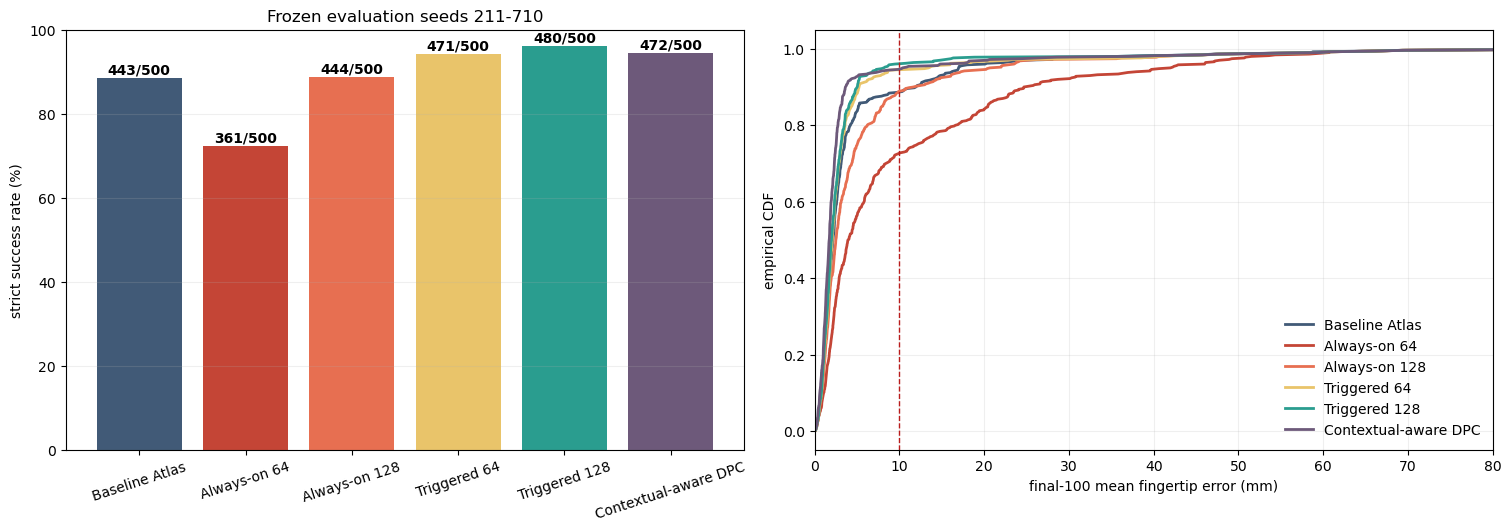

In [5]:
def wilson(successes, trials, z=1.959963984540054):
    p = successes / trials
    den = 1 + z*z/trials
    center = (p + z*z/(2*trials))/den
    half = z*math.sqrt(p*(1-p)/trials + z*z/(4*trials**2))/den
    return center-half, center+half

evaluation_methods = {
    'Baseline Atlas': eval_atlas,
    'Always-on 64': eval_always64,
    'Always-on 128': eval_always128,
    'Triggered 64': eval_trigger64,
    'Triggered 128': eval_cluster,
    'Contextual-aware DPC': eval_contextual,
}
outcome_rows = []
for method, rows in evaluation_methods.items():
    count = sum(strict(rows[seed]) for seed in EVAL_SEEDS)
    low, high = wilson(count, len(EVAL_SEEDS))
    outcome_rows.append({
        'method': method, 'successes': count, 'failures': len(EVAL_SEEDS)-count,
        'success rate': count/len(EVAL_SEEDS), '95% Wilson CI': f'[{low:.3f}, {high:.3f}]',
        'median final-100 (mm)': np.median([1000*rows[s]['mean_last_100'] for s in EVAL_SEEDS]),
    })
outcome_table = pd.DataFrame(outcome_rows).set_index('method')
display(outcome_table.style.format({'success rate': '{:.1%}', 'median final-100 (mm)': '{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)
palette = ['#415a77', '#c44536', '#e76f51', '#e9c46a', '#2a9d8f', '#6d597a']
bars = axes[0].bar(outcome_table.index, 100*outcome_table['success rate'], color=palette)
axes[0].set(ylabel='strict success rate (%)', ylim=(0, 100), title='Frozen evaluation seeds 211-710')
axes[0].tick_params(axis='x', rotation=18)
axes[0].grid(axis='y', alpha=0.2)
for bar, value in zip(bars, outcome_table['successes']):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{value}/500', ha='center', fontweight='bold')
for method, rows, color in zip(evaluation_methods, evaluation_methods.values(), palette):
    values = np.sort([1000*rows[s]['mean_last_100'] for s in EVAL_SEEDS])
    axes[1].plot(values, np.arange(1, len(values)+1)/len(values), label=method, color=color, linewidth=2)
axes[1].axvline(10, color='#b91c1c', linestyle='--', linewidth=1)
axes[1].set(xlabel='final-100 mean fingertip error (mm)', ylabel='empirical CDF', xlim=(0, 80))
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.2)
plt.show()

The 500-seed panel confirms the development pattern. Increasing always-on resolution from 64 to 128 prototypes raises success from 361/500 (72.2%) to 444/500 (88.8%), but always-on 128 is statistically tied with the 443/500 (88.6%) physical baseline. Contextual information alone does not dominate physically localized control.

The trigger changes the result: triggered 64 reaches 471/500 (94.2%), essentially matching global contextual-aware DPC at 472/500 (94.4%), while triggered 128 reaches the best aggregate result, 480/500 (96.0%). Thus both gating and contextual resolution matter. The trigger protects nominal physical-chart behavior; the larger codebook provides a more precise rescue basis when that behavior stalls.

## 4. Paired seed analysis

In [6]:
def exact_mcnemar(first_only, second_only):
    n = first_only + second_only
    if n == 0: return 1.0
    return min(1.0, 2*sum(math.comb(n,k) for k in range(min(first_only,second_only)+1))/2**n)

def paired(first_name, first, second_name, second):
    first_only = [s for s in EVAL_SEEDS if strict(first[s]) and not strict(second[s])]
    second_only = [s for s in EVAL_SEEDS if not strict(first[s]) and strict(second[s])]
    return {
        'comparison': f'{second_name} vs {first_name}',
        'first-only': len(first_only), 'second-only': len(second_only),
        'net successes': len(second_only)-len(first_only),
        'exact McNemar p': exact_mcnemar(len(first_only), len(second_only)),
        'first-only seeds': first_only, 'second-only seeds': second_only,
    }

paired_rows = [
    paired('Baseline Atlas', eval_atlas, 'Always-on 128', eval_always128),
    paired('Always-on 64', eval_always64, 'Triggered 64', eval_trigger64),
    paired('Always-on 128', eval_always128, 'Triggered 128', eval_cluster),
    paired('Baseline Atlas', eval_atlas, 'Triggered 64', eval_trigger64),
    paired('Baseline Atlas', eval_atlas, 'Triggered 128', eval_cluster),
    paired('Contextual-aware DPC', eval_contextual, 'Triggered 64', eval_trigger64),
    paired('Contextual-aware DPC', eval_contextual, 'Triggered 128', eval_cluster),
    paired('Triggered 64', eval_trigger64, 'Triggered 128', eval_cluster),
]
display(pd.DataFrame([{k:v for k,v in row.items() if not k.endswith('seeds')} for row in paired_rows]).set_index('comparison'))
display(pd.Series({
    'triggered-128 repairs over baseline': paired_rows[4]['second-only seeds'],
    'triggered-128 regressions from baseline': paired_rows[4]['first-only seeds'],
    'triggered-128-only vs contextual-aware': paired_rows[6]['second-only seeds'],
    'contextual-aware-only vs triggered-128': paired_rows[6]['first-only seeds'],
}, dtype=object))

,first-only,second-only,net successes,exact McNemar p
comparison,,,,
Always-on 128 vs Baseline Atlas,39,40,1,1.000000e+00
Triggered 64 vs Always-on 64,1,111,110,4.352602e-32
Triggered 128 vs Always-on 128,0,36,36,2.910383e-11
Triggered 64 vs Baseline Atlas,2,30,28,2.463348e-07
Triggered 128 vs Baseline Atlas,3,40,37,3.021341e-09
Triggered 64 vs Contextual-aware DPC,12,11,-1,1.000000e+00
Triggered 128 vs Contextual-aware DPC,6,14,8,1.153183e-01
Triggered 128 vs Triggered 64,2,11,9,2.246094e-02


triggered-128 repairs over baseline        [232, 247, 254, 266, 283, 288, 299, 319, 325, ...
triggered-128 regressions from baseline                                      [231, 660, 690]
triggered-128-only vs contextual-aware     [229, 236, 283, 290, 294, 296, 299, 336, 436, ...
contextual-aware-only vs triggered-128                        [369, 405, 423, 526, 645, 660]
dtype: object

## 5. Online computation

,localization (ms),routing (ms),selection / prototype score (ms),online SVD (ms),QP solve (ms),total control (ms)
method,,,,,,
Baseline Atlas,0.066,0.005,0.000,0.000,45.144,45.296
Always-on 64,0.067,0.014,0.155,0.000,52.833,53.244
Always-on 128,0.067,0.014,0.172,0.000,50.931,51.423
Triggered 64,0.068,0.014,0.001,0.000,49.226,49.441
Triggered 128,0.067,0.014,0.001,0.000,51.823,52.000
Contextual-aware DPC,0.064,0.015,29.995,2.364,44.892,78.462


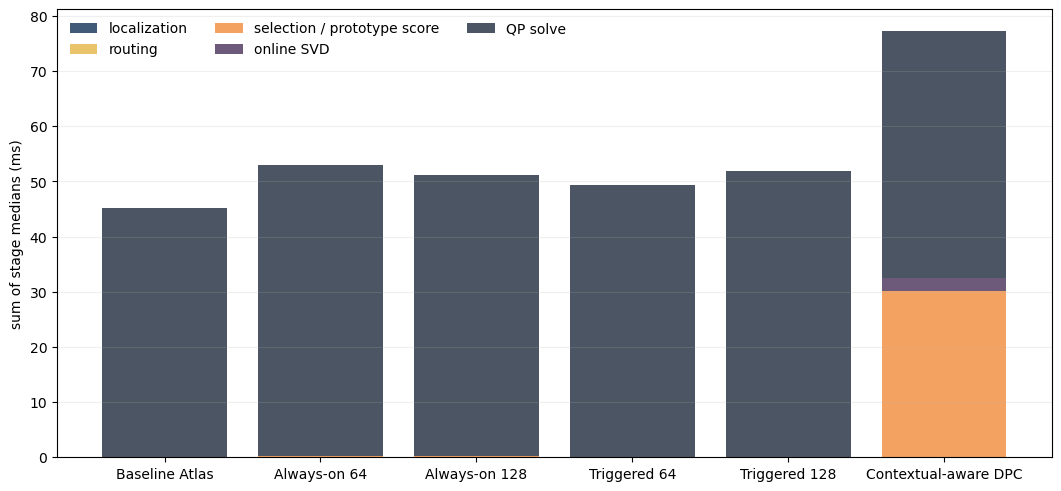

triggered rollouts                             59.000000
triggered rollout fraction                      0.118000
mean contextual step fraction                   0.098994
prototype count scored on contextual steps    128.000000
Hankel columns scored online                    0.000000
online SVD rebuilds                             0.000000
cached artifact size (MB)                      12.188455
dtype: float64

In [7]:
timing_fields = {
    'Baseline Atlas': ('median_localization_time_ms', 'median_routing_time_ms', None, None, 'median_solve_time_ms', 'median_control_compute_time_ms'),
    'Always-on 64': ('median_localization_ms', 'median_routing_ms', 'median_cluster_scoring_ms', None, 'median_solve_ms', 'median_control_compute_ms'),
    'Always-on 128': ('median_localization_ms', 'median_routing_ms', 'median_cluster_scoring_ms', None, 'median_solve_ms', 'median_control_compute_ms'),
    'Triggered 64': ('median_localization_ms', 'median_routing_ms', 'median_cluster_scoring_ms', None, 'median_solve_ms', 'median_control_compute_ms'),
    'Triggered 128': ('median_localization_ms', 'median_routing_ms', 'median_cluster_scoring_ms', None, 'median_solve_ms', 'median_control_compute_ms'),
    'Contextual-aware DPC': ('median_localization_ms', 'median_routing_ms', 'median_selection_ms', 'median_svd_rebuild_ms', 'median_solve_ms', 'median_control_compute_ms'),
}
timing_rows = []
for method, rows in evaluation_methods.items():
    fields = timing_fields[method]
    values = {'method': method}
    for label, field in zip(['localization','routing','selection / prototype score','online SVD','QP solve','total control'], fields):
        values[f'{label} (ms)'] = 0.0 if field is None else float(np.median([rows[s][field] for s in EVAL_SEEDS]))
    timing_rows.append(values)
timing_table = pd.DataFrame(timing_rows).set_index('method')
display(timing_table.style.format('{:.3f}'))

stage_columns = ['localization (ms)','routing (ms)','selection / prototype score (ms)','online SVD (ms)','QP solve (ms)']
fig, ax = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
bottom = np.zeros(len(timing_table))
for column, color in zip(stage_columns, ['#415a77','#e9c46a','#f4a261','#6d597a','#4b5563']):
    values = timing_table[column].to_numpy()
    ax.bar(timing_table.index, values, bottom=bottom, label=column.removesuffix(' (ms)'), color=color)
    bottom += values
ax.set_ylabel('sum of stage medians (ms)')
ax.legend(frameon=False, ncol=3)
ax.grid(axis='y', alpha=0.2)
plt.show()

triggered = [row for row in eval_cluster.values() if row['contextual_triggered']]
display(pd.Series({
    'triggered rollouts': len(triggered),
    'triggered rollout fraction': len(triggered)/len(EVAL_SEEDS),
    'mean contextual step fraction': np.mean([row['contextual_usage_fraction'] for row in eval_cluster.values()]),
    'prototype count scored on contextual steps': eval_cluster_payload['artifact']['prototype_count'],
    'Hankel columns scored online': 0,
    'online SVD rebuilds': 0,
    'cached artifact size (MB)': (EVAL_CLUSTER_DIR/'contextual_cluster_atlas.npz').stat().st_size/1e6,
}))

The batch timing table is descriptive because the saved methods were produced in separate parallel runs. The optional controlled serial timing file below reruns both contextual methods on the same machine without worker contention; it is the stronger latency comparison.

In [8]:
if TIMING_PATH.exists():
    timing = json.loads(TIMING_PATH.read_text())
    display(pd.DataFrame(timing['methods']).set_index('method').style.format('{:.3f}', subset=['median control (ms)','p95 control (ms)','median selection (ms)','median SVD (ms)','median QP (ms)']))
else:
    print('Controlled serial timing has not been generated:', TIMING_PATH)

,control steps,median control (ms),p95 control (ms),median selection (ms),median SVD (ms),median QP (ms)
method,,,,,,
Contextual-aware DPC: all steps,960,68.123,104.402,21.953,4.001,41.005
Contextual-cluster Atlas: all steps,960,41.645,54.085,0.158,0.000,41.174
Contextual-cluster Atlas: active steps,770,42.088,51.884,0.180,0.000,41.650


## 6. Offline atlas diagnostics

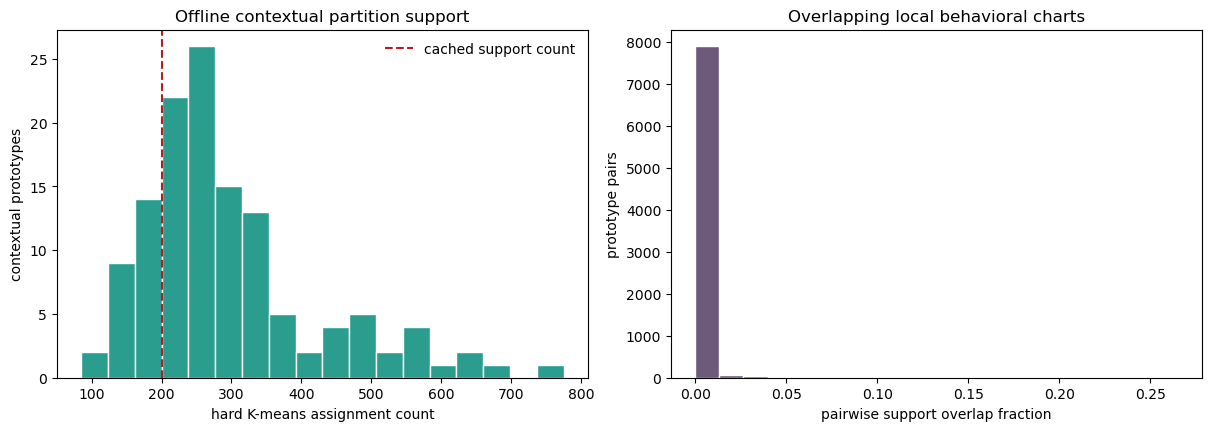

assignment count min                85.0
assignment count median            263.5
assignment count max               775.0
cached support per prototype       200.0
median pairwise support overlap      0.0
dtype: float64

In [9]:
artifact = np.load(EVAL_CLUSTER_DIR/'contextual_cluster_atlas.npz', allow_pickle=True)
counts = np.asarray(artifact['assignment_counts'], dtype=int)
supports = np.asarray(artifact['support_indices'], dtype=int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].hist(counts, bins=18, color='#2a9d8f', edgecolor='white')
axes[0].axvline(200, color='#b91c1c', linestyle='--', label='cached support count')
axes[0].set(xlabel='hard K-means assignment count', ylabel='contextual prototypes', title='Offline contextual partition support')
axes[0].legend(frameon=False)
overlap = []
for i in range(len(supports)):
    for j in range(i+1, len(supports)):
        overlap.append(np.intersect1d(supports[i], supports[j]).size/200)
axes[1].hist(overlap, bins=20, color='#6d597a', edgecolor='white')
axes[1].set(xlabel='pairwise support overlap fraction', ylabel='prototype pairs', title='Overlapping local behavioral charts')
plt.show()
display(pd.Series({
    'assignment count min': counts.min(), 'assignment count median': np.median(counts),
    'assignment count max': counts.max(), 'cached support per prototype': supports.shape[1],
    'median pairwise support overlap': np.median(overlap),
}))

## 7. Cached basis rank ablation

The prototype partition, 200-column support of every prototype, graph, trigger, costs, bounds, and all controller settings are frozen. Lower-rank artifacts are formed by taking the first $r$ columns of the **same** rank-60 SVD bases and the matching coordinate bounds. Thus rank is the only changing variable.

The broad scan uses ranks 20, 30, 40, 45, 50, and 60. A refined integer scan then evaluates every rank from 46 through 54 on development seeds 111--210. Ranks 47 and 49 tie for the best development result, 98/100; rank 47 is frozen by the lower-rank efficiency tie-break. Ranks 40 and 45 retain their earlier evaluation results as boundary and efficiency comparisons.

,successes,success rate,median final-100 (mm)
rank,,,
20,2,2.0%,86.851
30,54,54.0%,8.913
40,93,93.0%,4.569
45,97,97.0%,4.130
46,96,96.0%,4.021
47,98,98.0%,3.825
48,97,97.0%,3.783
49,98,98.0%,3.772
50,96,96.0%,4.300


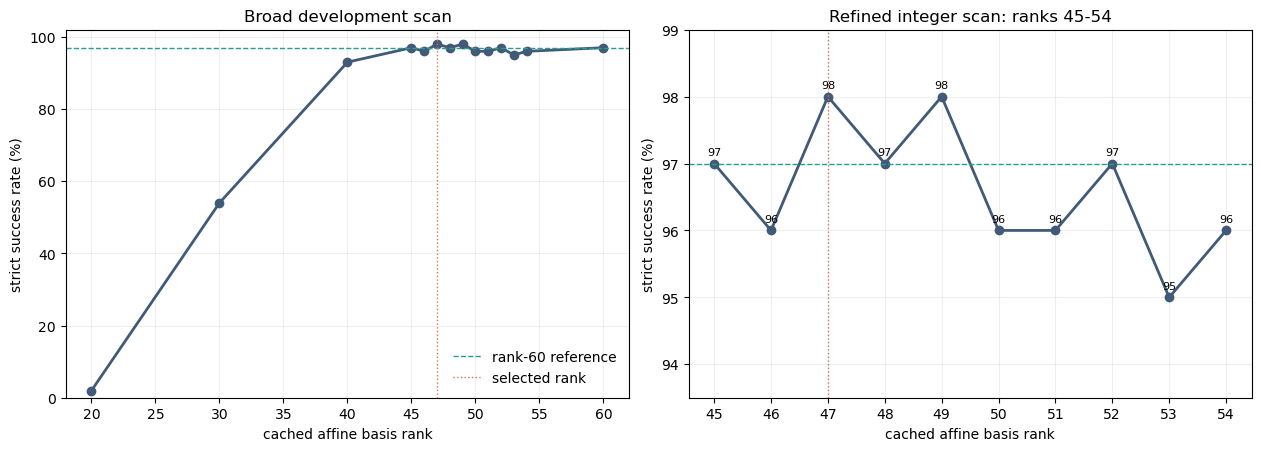

In [10]:
dev_rank_payloads = {}
dev_rank_rows = {}
for rank, directory in DEV_RANK_DIRS.items():
    dev_rank_payloads[rank], dev_rank_rows[rank] = load_rows(directory/'summary.json')
    assert set(dev_rank_rows[rank]) == set(DEV_SEEDS)
    assert all(row['svd_rank'] == rank for row in dev_rank_rows[rank].values())

eval_rank_payloads = {}
eval_rank_rows = {}
for rank, directory in EVAL_RANK_DIRS.items():
    eval_rank_payloads[rank], eval_rank_rows[rank] = load_rows(directory/'summary.json')
    assert set(eval_rank_rows[rank]) == set(EVAL_SEEDS)
    assert all(row['svd_rank'] == rank for row in eval_rank_rows[rank].values())

development_rank_table = pd.DataFrame([
    {
        'rank': rank,
        'successes': sum(strict(row) for row in rows.values()),
        'success rate': np.mean([strict(row) for row in rows.values()]),
        'median final-100 (mm)': np.median([1000*row['mean_last_100'] for row in rows.values()]),
    }
    for rank, rows in sorted(dev_rank_rows.items())
]).set_index('rank')
display(development_rank_table.style.format({'success rate':'{:.1%}', 'median final-100 (mm)':'{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), constrained_layout=True)
axes[0].plot(development_rank_table.index, 100*development_rank_table['success rate'], marker='o', linewidth=2, color='#415a77')
axes[0].axhline(97, color='#2a9d8f', linestyle='--', linewidth=1, label='rank-60 reference')
axes[0].axvline(47, color='#e76f51', linestyle=':', linewidth=1, label='selected rank')
axes[0].set(xlabel='cached affine basis rank', ylabel='strict success rate (%)', ylim=(0, 102), title='Broad development scan')
axes[0].grid(alpha=0.2)
axes[0].legend(frameon=False)

refined = development_rank_table.loc[45:54]
axes[1].plot(refined.index, 100*refined['success rate'], marker='o', linewidth=2, color='#415a77')
axes[1].axhline(97, color='#2a9d8f', linestyle='--', linewidth=1, label='rank-60 reference')
axes[1].axvline(47, color='#e76f51', linestyle=':', linewidth=1, label='selected rank')
axes[1].set(xlabel='cached affine basis rank', ylabel='strict success rate (%)', ylim=(93.5, 99), title='Refined integer scan: ranks 45-54')
axes[1].set_xticks(refined.index)
axes[1].grid(alpha=0.2)
for rank, successes in refined['successes'].items():
    axes[1].annotate(str(successes), (rank, successes), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8)
plt.show()

,successes,success rate,95% Wilson CI,median final-100 (mm),parallel-batch median control (ms),artifact (MB)
rank,,,,,,
40,462,92.4%,"[0.897, 0.944]",4.603,40.304,8.25
45,472,94.4%,"[0.920, 0.961]",4.424,47.190,9.23
47,472,94.4%,"[0.920, 0.961]",3.992,53.149,9.63
60,480,96.0%,"[0.939, 0.974]",1.991,52.000,12.19


,first-only,second-only,net successes,exact McNemar p
comparison,,,,
rank 40 vs rank 60,24,6,-18,0.001431
rank 45 vs rank 60,12,4,-8,0.076813
rank 47 vs rank 60,13,5,-8,0.096252


rank 45 regressions from rank 60    [290, 325, 326, 408, 413, 450, 451, 484, 557, ...
rank 45 repairs over rank 60                                     [369, 405, 423, 690]
rank 47 regressions from rank 60    [290, 325, 326, 336, 408, 450, 451, 484, 557, ...
rank 47 repairs over rank 60                                [231, 369, 405, 423, 690]
dtype: object

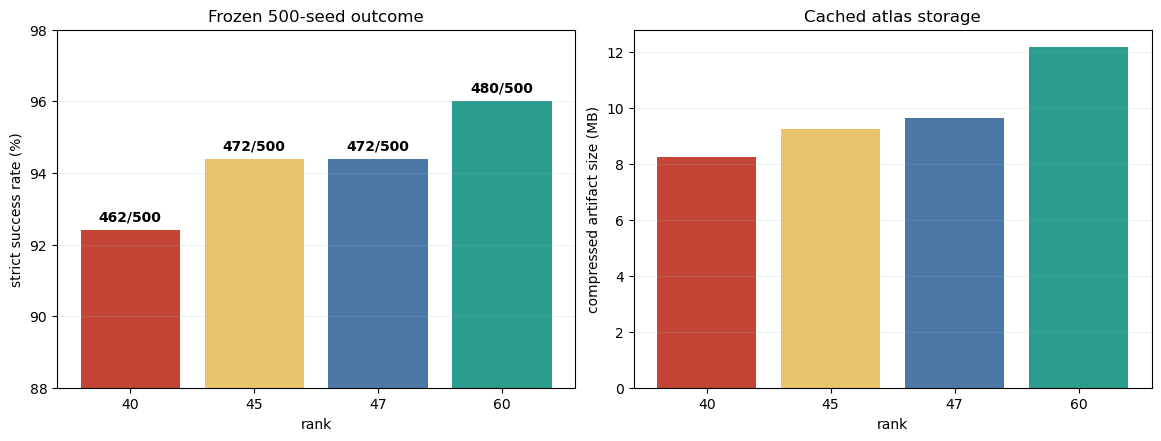

In [11]:
evaluation_rank_rows = []
for rank, rows in sorted(eval_rank_rows.items()):
    successes = sum(strict(row) for row in rows.values())
    low, high = wilson(successes, len(EVAL_SEEDS))
    evaluation_rank_rows.append({
        'rank': rank,
        'successes': successes,
        'success rate': successes/len(EVAL_SEEDS),
        '95% Wilson CI': f'[{low:.3f}, {high:.3f}]',
        'median final-100 (mm)': np.median([1000*row['mean_last_100'] for row in rows.values()]),
        'parallel-batch median control (ms)': np.median([row['median_control_compute_ms'] for row in rows.values()]),
        'artifact (MB)': (EVAL_RANK_DIRS[rank]/'contextual_cluster_atlas.npz').stat().st_size/1e6,
    })
evaluation_rank_table = pd.DataFrame(evaluation_rank_rows).set_index('rank')
display(evaluation_rank_table.style.format({
    'success rate':'{:.1%}', 'median final-100 (mm)':'{:.3f}',
    'parallel-batch median control (ms)':'{:.3f}', 'artifact (MB)':'{:.2f}',
}))

rank60 = eval_rank_rows[60]
paired_rank_rows = []
for rank in (40,45,47):
    result = paired('rank 60', rank60, f'rank {rank}', eval_rank_rows[rank])
    paired_rank_rows.append(result)
display(pd.DataFrame([
    {k:v for k,v in row.items() if not k.endswith('seeds')}
    for row in paired_rank_rows
]).set_index('comparison'))
display(pd.Series({
    'rank 45 regressions from rank 60': paired_rank_rows[1]['first-only seeds'],
    'rank 45 repairs over rank 60': paired_rank_rows[1]['second-only seeds'],
    'rank 47 regressions from rank 60': paired_rank_rows[2]['first-only seeds'],
    'rank 47 repairs over rank 60': paired_rank_rows[2]['second-only seeds'],
}, dtype=object))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), constrained_layout=True)
colors = ['#c44536','#e9c46a','#4c78a8','#2a9d8f']
axes[0].bar(evaluation_rank_table.index.astype(str), 100*evaluation_rank_table['success rate'], color=colors)
axes[0].set(xlabel='rank', ylabel='strict success rate (%)', ylim=(88,98), title='Frozen 500-seed outcome')
axes[0].grid(axis='y', alpha=0.2)
for x, value in enumerate(evaluation_rank_table['successes']):
    axes[0].text(x, 100*evaluation_rank_table['success rate'].iloc[x]+0.25, f'{value}/500', ha='center', fontweight='bold')
axes[1].bar(evaluation_rank_table.index.astype(str), evaluation_rank_table['artifact (MB)'], color=colors)
axes[1].set(xlabel='rank', ylabel='compressed artifact size (MB)', title='Cached atlas storage')
axes[1].grid(axis='y', alpha=0.2)
plt.show()

In [12]:
rank_timing = json.loads(RANK_TIMING_PATH.read_text())
rank_timing_table = pd.DataFrame(rank_timing['methods']).set_index(['scope','rank']).sort_index()
display(rank_timing_table.style.format('{:.3f}'))

all_steps = rank_timing_table.loc['all steps']
active_steps = rank_timing_table.loc['context-active steps']
display(pd.Series({
    'selected rank reduction': '60 -> 47 (21.7%)',
    'rank-47 all-step median control reduction': 1-all_steps.loc[47,'median control (ms)']/all_steps.loc[60,'median control (ms)'],
    'rank-47 context-active median QP reduction': 1-active_steps.loc[47,'median QP (ms)']/active_steps.loc[60,'median QP (ms)'],
    'rank-47 all-step p95 control reduction': 1-all_steps.loc[47,'p95 control (ms)']/all_steps.loc[60,'p95 control (ms)'],
    'rank-47 artifact size reduction': 1-evaluation_rank_table.loc[47,'artifact (MB)']/evaluation_rank_table.loc[60,'artifact (MB)'],
    'rank-45 median control reduction': 1-all_steps.loc[45,'median control (ms)']/all_steps.loc[60,'median control (ms)'],
}).to_frame('value').style.format({'value': lambda value: f'{value:.1%}' if isinstance(value, float) else value}))

,value
selected rank reduction,60 -> 47 (21.7%)
rank-47 all-step median control reduction,12.8%
rank-47 context-active median QP reduction,12.1%
rank-47 all-step p95 control reduction,18.3%
rank-47 artifact size reduction,21.0%
rank-45 median control reduction,16.2%


The refined scan does not reveal a hidden accuracy optimum near rank 50. Development-selected rank 47 obtains 472/500, the same aggregate success as rank 45 and below rank 60's 480/500. Against rank 60, its paired difference is not significant at 5% ($p=0.0963$), but it does not recover the numerical accuracy gap. Rank 47 reduces median same-process control latency by about 13% and cached storage by about 21%.

Rank 45 and rank 47 exchange three successes each, while rank 45 is faster and smaller. Therefore rank 45 remains the empirical efficiency point, rank 60 remains the accuracy-first setting, and rank 47 is useful evidence that the conclusion is stable to a refined search rather than a coarse-grid accident.

## Interpretation

The experiment tests a concrete middle ground between a fixed physical atlas and full online Contextual Sampling. The reference does not cause online re-clustering: it gates a fixed collection of overlapping contextual charts. Successful nominal graph-routed Atlas behavior remains active until a measured terminal stall; only then does the controller select a reference-conditioned cached basis.

The method should be considered successful only if the frozen 500-seed panel shows a success rate statistically comparable to contextual-aware DPC while eliminating its global column scan and online SVD. The tables above report that comparison directly rather than inferring it from a few representative trajectories.

## Reproduce or extend

In [13]:
RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    import contextual_cluster_atlas_experiment as experiment
    cfg = experiment.ContextualClusterConfig(
        architecture='global_vq', contextual_clusters=128,
        support_columns=200, activation_mode='triggered',
        error_threshold=0.01, stall_window=15, minimum_progress=0.001,
    )
    experiment.run_panel(
        EVAL_SEEDS, RESULT_ROOT/'clustering_jointconfig48_fresh211_310',
        EVAL_CLUSTER_DIR, cfg, workers=8, overwrite=False,
    )
else:
    print('Using completed saved results. Set RUN_EXPERIMENTS=True to resume/rerun.')

Using completed saved results. Set RUN_EXPERIMENTS=True to resume/rerun.
